## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

## Setup

In [2]:
assert os.path.exists("weights_V3_1/classification_lightgbm_kfold_metrics.json"), "oracle must run first"
SEED = 42
np.random.seed(SEED)
boost_rng = np.random.RandomState(SEED)
os.makedirs("weights_V3_1", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = [
    "AcceptedCmp5", "AcceptedCmp3", "MntWines", "MntMeatProducts",
    "NumCatalogPurchases", "Recency", "Customer_Tenure_Days", "MntGoldProds",
    "Income", "MntFruits",
    "AcceptedCmp1", "AcceptedCmp2", "NumWebPurchases", "MntSweetProducts",
    "MntFishProducts", "NumStorePurchases", "Age",
]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
inc_idx = FEATURE_COLS.index("Income")
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


## Model

In [4]:
def best_split(X, g, h, feat_idx, reg_lambda, min_leaf):
    G_tot, H_tot = g.sum(), h.sum()
    parent = 0.5 * (G_tot ** 2 / (H_tot + reg_lambda))
    best_gain, best_feat, best_thresh = 0.0, None, None
    for f in feat_idx:
        order = np.argsort(X[:, f], kind="mergesort")
        xs, gs, hs = X[order, f], g[order], h[order]
        n = len(xs)
        if n < 2 * min_leaf:
            continue
        cG, cH = np.cumsum(gs), np.cumsum(hs)
        GL, HL = cG[:-1], cH[:-1]
        GR, HR = G_tot - GL, H_tot - HL
        left_n = np.arange(1, n); right_n = n - left_n
        valid = (xs[:-1] != xs[1:]) & (left_n >= min_leaf) & (right_n >= min_leaf)
        if not valid.any():
            continue
        gain = 0.5 * (GL ** 2 / (HL + reg_lambda) + GR ** 2 / (HR + reg_lambda)) - parent
        gain = np.where(valid, gain, -np.inf)
        idx = np.argmax(gain)
        if gain[idx] > best_gain:
            best_gain, best_feat = gain[idx], f
            best_thresh = (xs[idx] + xs[idx + 1]) / 2.0
    return best_feat, best_thresh, best_gain

In [5]:
def build_tree(X, g, h, feat_idx, reg_lambda, min_leaf, max_depth, depth=0):
    G, H = g.sum(), h.sum()
    leaf_val = -G / (H + reg_lambda)
    if depth >= max_depth or len(g) < 2 * min_leaf:
        return {"leaf": True, "value": float(leaf_val)}
    f, thresh, gain = best_split(X, g, h, feat_idx, reg_lambda, min_leaf)
    if f is None or gain <= 1e-12:
        return {"leaf": True, "value": float(leaf_val)}
    mask = X[:, f] <= thresh
    left = build_tree(X[mask], g[mask], h[mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    right = build_tree(X[~mask], g[~mask], h[~mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    return {"leaf": False, "feature": int(f), "threshold": float(thresh), "left": left, "right": right}

In [6]:
def tree_predict(node, X):
    if X.shape[0] == 0:
        return np.empty(0)
    if node["leaf"]:
        return np.full(X.shape[0], node["value"])
    out = np.empty(X.shape[0])
    mask = X[:, node["feature"]] <= node["threshold"]
    out[mask] = tree_predict(node["left"], X[mask])
    out[~mask] = tree_predict(node["right"], X[~mask])
    return out

In [7]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

In [8]:
MAX_DEPTH, MIN_SAMPLES_LEAF, REG_LAMBDA = 5, 20, 1.0
LEARNING_RATE, N_ROUNDS, PATIENCE = 0.05, 500, 50
ROW_SUBSAMPLE, COL_SUBSAMPLE = 0.8, 0.8
print(f"max_depth={MAX_DEPTH} min_samples_leaf={MIN_SAMPLES_LEAF} reg_lambda={REG_LAMBDA} "
      f"lr={LEARNING_RATE} n_rounds={N_ROUNDS} patience={PATIENCE} row_sub={ROW_SUBSAMPLE} col_sub={COL_SUBSAMPLE}")

max_depth=5 min_samples_leaf=20 reg_lambda=1.0 lr=0.05 n_rounds=500 patience=50 row_sub=0.8 col_sub=0.8


## Sanity Check

In [9]:
from sklearn.tree import DecisionTreeRegressor
rng_chk = np.random.RandomState(0)
X_chk = rng_chk.randn(60, 3)
y_chk = 2 * X_chk[:, 0] - X_chk[:, 1] + 0.1 * rng_chk.randn(60)
g_chk, h_chk = -y_chk, np.ones(60)
my_tree = build_tree(X_chk, g_chk, h_chk, list(range(3)), reg_lambda=0.0, min_leaf=1, max_depth=2)
my_pred = tree_predict(my_tree, X_chk)
sk_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=1).fit(X_chk, y_chk)
sk_pred = sk_tree.predict(X_chk)
diff_a = float(np.max(np.abs(my_pred - sk_pred)))
print(f"sanity A: max|our_tree - sklearn_tree| = {diff_a:.3e}")
assert diff_a < 1e-9, "sanity check A FAILED"

sanity A: max|our_tree - sklearn_tree| = 4.441e-16


In [10]:
y_toy = np.array([1.0, 2.0, 3.0]); X_toy = np.zeros((3, 1))
F_toy = np.full(3, 0.0); lr_toy = 0.1
expected_F_after_round = [0.2, 0.38]
toy_losses = []
for r in range(20):
    g_toy, h_toy = F_toy - y_toy, np.ones(3)
    stump = build_tree(X_toy, g_toy, h_toy, [0], reg_lambda=0.0, min_leaf=1, max_depth=0)
    F_toy = F_toy + lr_toy * tree_predict(stump, X_toy)
    if r < 2:
        assert abs(F_toy[0] - expected_F_after_round[r]) < 1e-9, "sanity check B FAILED"
    toy_losses.append(float(np.mean((F_toy - y_toy) ** 2)))
assert all(toy_losses[i] >= toy_losses[i + 1] - 1e-12 for i in range(len(toy_losses) - 1)), "sanity check B FAILED (monotonic)"
print(f"sanity B: closed-form F match | 20-round toy loss monotonic: {toy_losses[0]:.4f} -> {toy_losses[-1]:.4f}")
print("ALL SANITY CHECKS PASSED")

sanity B: closed-form F match | 20-round toy loss monotonic: 3.9067 -> 0.7258
ALL SANITY CHECKS PASSED


## Training

In [11]:
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
X_all = X_full.values
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_all, y_full), start=1):
    Xtr_f, Xva_f = X_all[tr_idx].copy(), X_all[va_idx].copy()
    ytr_f, yva_f = y_full[tr_idx], y_full[va_idx]
    med_f = np.nanmedian(Xtr_f[:, inc_idx])
    for arr in (Xtr_f, Xva_f):
        arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), med_f, arr[:, inc_idx])

    pos_f, neg_f = (ytr_f == 1).sum(), (ytr_f == 0).sum()
    scale_pos_weight_f = neg_f / pos_f

    X_tr, X_val, y_tr, y_val = train_test_split(
        Xtr_f, ytr_f, test_size=0.10, random_state=SEED, stratify=ytr_f)

    n_tr, n_feat = X_tr.shape
    n_sub_rows = max(MIN_SAMPLES_LEAF * 2, int(round(ROW_SUBSAMPLE * n_tr)))
    n_sub_cols = max(1, int(round(COL_SUBSAMPLE * n_feat)))

    p0 = float(y_tr.mean())
    F0 = float(np.log(p0 / (1 - p0)))
    F_tr, F_val = np.full(n_tr, F0), np.full(len(y_val), F0)

    trees = []
    best_val, best_round, wait = np.inf, 0, 0
    for r in range(1, N_ROUNDS + 1):
        p_tr = sigmoid(F_tr)
        w = np.where(y_tr == 1, scale_pos_weight_f, 1.0)
        g_full = w * (p_tr - y_tr)
        h_full = w * p_tr * (1 - p_tr)

        row_idx = boost_rng.choice(n_tr, size=n_sub_rows, replace=False)
        col_idx = boost_rng.choice(n_feat, size=n_sub_cols, replace=False)
        tree = build_tree(X_tr[row_idx], g_full[row_idx], h_full[row_idx], col_idx,
                           REG_LAMBDA, MIN_SAMPLES_LEAF, MAX_DEPTH)
        trees.append(tree)

        F_tr = F_tr + LEARNING_RATE * tree_predict(tree, X_tr)
        F_val = F_val + LEARNING_RATE * tree_predict(tree, X_val)

        p_val_c = np.clip(sigmoid(F_val), 1e-12, 1 - 1e-12)
        val_bce = float(-(y_val * np.log(p_val_c) + (1 - y_val) * np.log(1 - p_val_c)).mean())

        if val_bce < best_val - 1e-9:
            best_val, best_round, wait = val_bce, r, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    trees = trees[:best_round]

    F_va = np.full(Xva_f.shape[0], F0)
    for t in trees:
        F_va = F_va + LEARNING_RATE * tree_predict(t, Xva_f)
    prob_v = sigmoid(F_va); pred_v = (prob_v >= 0.5).astype(int)
    fold_rows.append({
        "fold": fold,
        "best_iteration": int(best_round),
        "test_loss_BCE": round(float(log_loss(yva_f, prob_v)), 4),
        "accuracy": round(float(accuracy_score(yva_f, pred_v)), 4),
        "precision": round(float(precision_score(yva_f, pred_v, zero_division=0)), 4),
        "recall": round(float(recall_score(yva_f, pred_v, zero_division=0)), 4),
        "f1": round(float(f1_score(yva_f, pred_v, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(yva_f, prob_v)), 4),
    })
    print(f"fold {fold}: F1={fold_rows[-1]['f1']:.4f} BCE={fold_rows[-1]['test_loss_BCE']:.4f} best_iter={best_round}")

fold 1: F1=0.6107 BCE=0.2533 best_iter=369


fold 2: F1=0.5390 BCE=0.3447 best_iter=235


fold 3: F1=0.6494 BCE=0.2809 best_iter=297


fold 4: F1=0.5324 BCE=0.3124 best_iter=256


fold 5: F1=0.5538 BCE=0.2928 best_iter=263


## K-Fold Summary

In [12]:
kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_loss_BCE", "accuracy", "precision", "recall", "f1", "roc_auc")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V3_1/classification_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

 fold  best_iteration  test_loss_BCE  accuracy  precision  recall     f1  roc_auc
    1             369         0.2533    0.8862     0.6250  0.5970 0.6107   0.9191
    2             235         0.3447    0.8546     0.5135  0.5672 0.5390   0.8607
    3             297         0.2809    0.8792     0.5747  0.7463 0.6494   0.9104
    4             256         0.3124    0.8546     0.5139  0.5522 0.5324   0.8834
    5             263         0.2928    0.8702     0.5625  0.5455 0.5538   0.8812
{
  "test_loss_BCE": {
    "mean": 0.2968,
    "std": 0.0343
  },
  "accuracy": {
    "mean": 0.869,
    "std": 0.0143
  },
  "precision": {
    "mean": 0.5579,
    "std": 0.0467
  },
  "recall": {
    "mean": 0.6016,
    "std": 0.0833
  },
  "f1": {
    "mean": 0.5771,
    "std": 0.0509
  },
  "roc_auc": {
    "mean": 0.891,
    "std": 0.0237
  }
}


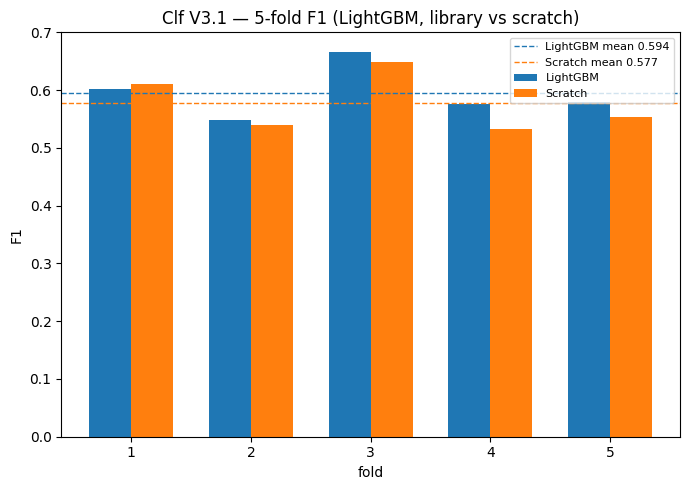

LightGBM F1 mean+-std: 0.5944 0.0447
Scratch  F1 mean+-std: 0.5771 0.0509
per-fold best_iteration (scratch): [369, 235, 297, 256, 263]


In [13]:
import matplotlib.pyplot as plt

lib_kf = json.load(open("weights_V3_1/classification_lightgbm_kfold_metrics.json"))
scr_kf = json.load(open("weights_V3_1/classification_scratch_kfold_metrics.json"))
lib_f1 = [r["f1"] for r in lib_kf["folds"]]
scr_f1 = [r["f1"] for r in scr_kf["folds"]]
folds_x = np.arange(1, K + 1)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, lib_f1, width, label="LightGBM")
plt.bar(folds_x + width / 2, scr_f1, width, label="Scratch")
plt.axhline(lib_kf["summary"]["f1"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"LightGBM mean {lib_kf['summary']['f1']['mean']:.3f}")
plt.axhline(scr_kf["summary"]["f1"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean {scr_kf['summary']['f1']['mean']:.3f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("F1")
plt.title("Clf V3.1 — 5-fold F1 (LightGBM, library vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_clf_V3_1.png", dpi=150)
plt.show()

print("LightGBM F1 mean+-std:", lib_kf["summary"]["f1"]["mean"], lib_kf["summary"]["f1"]["std"])
print("Scratch  F1 mean+-std:", scr_kf["summary"]["f1"]["mean"], scr_kf["summary"]["f1"]["std"])
print("per-fold best_iteration (scratch):", [r["best_iteration"] for r in scr_kf["folds"]])